# 2. Regional SST teleconnections

Compare the correlation between a regional SST index and a gridded field in observations,
SamudrACE, and E3SM. Each column uses that system's own SST index and downstream field
(this is not forecast ACC). As in ESP-Lab's `3b_sst_telecon.ipynb`, model fields are
ensemble means and the comparisons use matched verification months. Here, as in
`1-nRMSE-ACC.ipynb`, leads represent individual months; lead 0 is the initialization month.

Start with `TARGET_VARIABLES = ["PRECT"]` for precipitation or edit the list to run several
fields in one pass. Select the **E3SM-Unified** kernel (`e3sm_env` in `.bashrc`).

In [1]:
%load_ext autoreload
%autoreload 2
import sys
from calendar import month_abbr
from contextlib import ExitStack
from pathlib import Path

ESP_LAB_ROOT = Path("/pscratch/sd/e/edejong/ESP-Lab")
if str(ESP_LAB_ROOT) not in sys.path:
    sys.path.insert(0, str(ESP_LAB_ROOT))

import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
from IPython.display import display

from esp_lab.diagnostics.sst_index import BASIC_REGIONS, HELPER_REGIONS
from esp_lab.utils.netcdf_utils import atomic_to_netcdf
from workflows.diagnostics import sst_teleconnections as telecon

plt.rcParams["font.size"] = 11

/global/common/software/e3sm/anaconda_envs/e3smu_1_13_0/pm-cpu/pixi_login/.pixi/envs/default/lib/python3.13/site-packages/properscoring/_crps.py:257: SyntaxWarning: invalid escape sequence '\i'
  CRPS(F, x) = \int_z (F(z) - H(z - x))^2 dz
/global/common/software/e3sm/anaconda_envs/e3smu_1_13_0/pm-cpu/pixi_login/.pixi/envs/default/lib/python3.13/site-packages/properscoring/_brier.py:10: SyntaxWarning: invalid escape sequence '\i'
  The Brier score (BS) scores binary forecasts $k \in \{0, 1\}$,
/global/common/software/e3sm/anaconda_envs/e3smu_1_13_0/pm-cpu/pixi_login/.pixi/envs/default/lib/python3.13/site-packages/properscoring/_brier.py:102: SyntaxWarning: invalid escape sequence '\i'
  CRPS(F, x) = \int_z BS(F(z), H(z - x)) dz


## Configuration

Inputs follow the merged-file naming in `1-nRMSE-ACC.ipynb`. The SST index uses
ocean-masked model `TS` (the SST proxy in that notebook) and HadISST2 `SST`.
For a downstream `SST` map, the same source choices and ocean mask apply;
downstream `TS` instead uses the full surface field with ERA5 as reference.

`PRECT`, `TS`, and `SST` have merged inputs for all three systems. `PSL`, `TREFHT`, and
`LHFLX` can also be selected once the corresponding merged files are available for
every selected system. To compare SamudrACE with observations for `LHFLX` using the
current archive, remove `"E3SM"` from `MODEL_SYSTEMS`.

In [ ]:
SAM_DIR = Path("/pscratch/sd/e/edejong/samudrace/hist-2y_runs_v0/analysis")
ANALYSIS_DIR = Path.cwd()
DATA_DIR = SAM_DIR / "merged"
FIGURE_DIR = ANALYSIS_DIR / "telecon_figures"
OUTPUT_DIR = ANALYSIS_DIR / "telecon_results"
LANDFRAC_FILE = Path("/pscratch/sd/e/edejong/samudrace/e3smv3-lr-hist-samudrace/forcing_data/atmosphere-forcing-1980.nc")
TARGET_GRID = "samudrace"
SAMUDRACE_CASE = "C1A1-01mo-EN00"
MODEL_SYSTEMS = ["SamudrACE", "E3SM"]

SST_INDICES = ["Nino3.4", "TNA"]
TARGET_VARIABLES = ["TS"]  # e.g. ["PRECT", "TS", "SST"]
INIT_MONTHS = [5, 11]
MAP_LEADS = [0, 3, 6, 12]
CLIM_YEARS = (1980, 2018)  # initialization years, as in 1-nRMSE
DETREND = True
MINIMUM_YEARS = 20
ALPHA = 0.05
PATTERN_LAT_BOUNDS = (-80, 80)
SAVE_RESULTS = True
SAVE_FIGURES = True

OBS_BY_VARIABLE = {"PRECT": "gpcp", "TS": "era5", "SST": "hadisst2", "PSL": "era5",
                   "TREFHT": "era5", "LHFLX": "era5"}
OBS_LABELS = {"gpcp": "GPCP", "era5": "ERA5", "hadisst2": "HadISST2"}
VARIABLE_LABELS = {"PRECT": "Precipitation", "TS": "Surface temperature", "SST": "SST",
                   "PSL": "Sea-level pressure", "TREFHT": "Near-surface air temperature",
                   "LHFLX": "Latent heat flux"}
MODEL_TAGS = {"SamudrACE": f"samudrace-{SAMUDRACE_CASE}", "E3SM": "e3sm"}
DISPLAY = {"SamudrACE": f"SamudrACE {SAMUDRACE_CASE}", "E3SM": "E3SM"}
REGION_BOXES = {name: region["lonlat"] for name, region in (BASIC_REGIONS | HELPER_REGIONS).items()}

## 1. Load and align merged inputs

For each downstream variable we use the intersection of starts across all selected
systems and verify the actual target year/month at every requested lead. The same
observed SST and downstream series are used for both model comparisons. Coverage can
differ by variable: for example, the merged GPCP file ends earlier than HadISST2.

In [8]:
def merged_input(system, variable):
    if system == "Obs":
        tag, field = OBS_BY_VARIABLE[variable], variable
    else:
        tag, field = MODEL_TAGS[system], "TS" if variable == "SST" else variable
    return DATA_DIR / f"{tag}_{field}_{TARGET_GRID}.nc", field


def ocean_mask(grid):
    with xr.open_dataset(LANDFRAC_FILE) as ds:
        frac = ds["LANDFRAC"]
        frac = (frac.isel(time=0, drop=True) if "time" in frac.dims else frac).load()
    for dim in ("lat", "lon"):
        if frac.sizes[dim] != grid.sizes[dim] or not np.allclose(frac[dim], grid[dim], atol=1e-5, rtol=0):
            raise ValueError(f"LANDFRAC {dim} is not on the merged target grid")
    return frac.assign_coords(lat=grid.lat, lon=grid.lon) < 0.5


def regional_sst(sst, name):
    if name == "IOD":
        return regional_sst(sst, "IOD_West") - regional_sst(sst, "IOD_East")
    west, east, south, north = REGION_BOXES[name]
    lon = sst.lon % 360
    in_lon = (lon >= west) & (lon <= east) if west <= east else (lon >= west) | (lon <= east)
    region = sst.where(in_lon & (sst.lat >= south) & (sst.lat <= north), drop=True)
    if min(region.sizes["lat"], region.sizes["lon"]) == 0:
        raise ValueError(f"No grid cells in SST region {name}")
    return region.weighted(np.cos(np.deg2rad(region.lat))).mean(("lat", "lon"))


def matched_fields(raw, starts, init_month, lead):
    selected = {spec: field.sel(start_date=starts, lead=lead) for spec, field in raw.items()}
    reference = next(iter(selected.values())).valid_time
    years, months = reference.dt.year.values, reference.dt.month.values
    init_years = reference.start_date.dt.year.values
    expected_years, expected_month = divmod(init_month - 1 + lead, 12)
    if not (np.array_equal(years, init_years + expected_years) and np.all(months == expected_month + 1)):
        raise ValueError(f"Unexpected verification dates for {month_abbr[init_month]} lead {lead}")
    for spec, field in selected.items():
        time = field.valid_time
        if not (np.array_equal(time.dt.year, years) and np.array_equal(time.dt.month, months)):
            raise ValueError(f"Verification month mismatch: {spec[0].name}, init {init_month}, lead {lead}")
    if not np.any((init_years >= CLIM_YEARS[0]) & (init_years <= CLIM_YEARS[1])):
        raise ValueError(f"No starts in climatology period {CLIM_YEARS} for init {init_month}")
    fields = {}
    for spec, field in selected.items():
        # Some merged source headers retain the original large missing-value sentinel.
        clean = field.where(np.isfinite(field) & (abs(field) < 1e30))
        mean = telecon.ensemble_mean(clean).drop_vars(["valid_time", "lead"]).load()
        mean.attrs = {}
        fields[spec] = mean
    return fields, reference

## 2. Compute teleconnection maps and pattern fidelity

Remove the climatological mean separately for each initialization month and lead.
If enabled, fit and remove a linear trend using the actual verification years.
ESP-Lab computes the pairwise Pearson $r$, pointwise p-value, and finite sample count.
P-values are nominal (not adjusted for autocorrelation, fitted trends, or multiple
comparisons); interpret significance hatching as descriptive. For pattern fidelity,
ESP-Lab compares the model and observed maps on their common finite cells, weighted
by cosine latitude within `PATTERN_LAT_BOUNDS`.

In [9]:
def prepare_sample(field, time):
    y = time.start_date.dt.year.values
    field = field.rename(start_date="Y").assign_coords(Y=y)
    anomaly = telecon.lead_anomaly(field, time, CLIM_YEARS)
    sample = anomaly.rename(Y="sample").assign_coords(sample=time.dt.year.values)
    if DETREND:
        # Use the same coordinates for fitting and evaluation, even with gaps in verification years.
        coef = sample.polyfit(dim="sample", deg=1, skipna=True).polyfit_coefficients
        sample = sample - xr.polyval(sample["sample"], coef)
    return sample


def compute_teleconnections(variable):
    systems = ["Obs", *MODEL_SYSTEMS]
    index_specs = {system: merged_input(system, "SST") for system in systems}
    field_specs = {system: merged_input(system, variable) for system in systems}
    specs = list(dict.fromkeys([*index_specs.values(), *field_specs.values()]))
    missing = [str(path) for path, _ in specs if not path.is_file()]
    if missing:
        raise FileNotFoundError("Missing merged inputs. Prepare observations with 0-regrid-obs.ipynb "
                                "and model fields with merge_datasets.py:\n" + "\n".join(missing))

    with ExitStack() as stack:
        raw = {}
        for path, field in specs:
            ds = stack.enter_context(xr.open_dataset(path, chunks={"lead": 1}))
            raw[path, field] = ds[field]
        grid = next(iter(raw.values()))
        mask = ocean_mask(grid)
        for (path, _), da in raw.items():
            if not (da.lat.equals(grid.lat) and da.lon.equals(grid.lon)):
                raise ValueError(f"Unexpected latitude/longitude coordinates in {path}")
            missing_leads = set(MAP_LEADS) - set(da.lead.values)
            if missing_leads:
                raise ValueError(f"Missing leads {sorted(missing_leads)} in {path}")
        common = grid.start_date.values
        for da in raw.values():
            common = np.intersect1d(common, da.start_date.values)

        by_init = []
        for init_month in INIT_MONTHS:
            starts = common[xr.DataArray(common, dims="start_date").dt.month.values == init_month]
            if len(starts) < MINIMUM_YEARS:
                raise ValueError(f"{variable}, {month_abbr[init_month]}: only {len(starts)} common starts "
                                 f"(need {MINIMUM_YEARS})")
            by_lead = []
            for lead in MAP_LEADS:
                fields, time = matched_fields(raw, starts, init_month, lead)
                by_system = []
                with np.errstate(divide="ignore", invalid="ignore"):
                    for system in systems:
                        sst = fields[index_specs[system]].where(mask)
                        target = sst if variable == "SST" else fields[field_specs[system]]
                        target = prepare_sample(target, time)
                        by_index = []
                        for name in SST_INDICES:
                            index = prepare_sample(regional_sst(sst, name), time)
                            r, p, n = telecon.corr_and_p(index, target, minimum_years=MINIMUM_YEARS)
                            by_index.append(xr.Dataset({
                                "correlation": r.assign_attrs(units="1", long_name="Pearson correlation"),
                                "pvalue": p.assign_attrs(units="1", long_name="Nominal two-sided p-value"),
                                "sample_count": n.assign_attrs(units="1", long_name="Finite paired samples"),
                            }).expand_dims(sst_index=[name]))
                        by_system.append(xr.concat(by_index, dim="sst_index").expand_dims(system=[system]))
                    maps = xr.concat(by_system, dim="system")
                    obs = maps.sel(system="Obs", drop=True)
                    model = maps.sel(system=MODEL_SYSTEMS).rename(system="model")
                    fidelity = telecon.weighted_spatial_metrics(
                        model.correlation, obs.correlation, model.pvalue, obs.pvalue,
                        latitude_bounds=PATTERN_LAT_BOUNDS, alpha=ALPHA,
                    )
                by_lead.append(xr.merge([maps, fidelity]).expand_dims(lead=[lead]).assign_coords(
                    verification_month=("lead", [int(time.dt.month.values[0])]),
                    verification_year_start=("lead", [int(time.dt.year.values.min())]),
                    verification_year_end=("lead", [int(time.dt.year.values.max())]),
                ))
            by_init.append(xr.concat(by_lead, dim="lead").expand_dims(init_month=[init_month]).assign_coords(
                common_start_count=("init_month", [len(starts)]),
            ))
            print(f"{variable}, {month_abbr[init_month]}: {len(starts)} common starts")
    return xr.concat(by_init, dim="init_month", coords="all").assign_attrs(
        variable=variable, observational_target=OBS_LABELS[OBS_BY_VARIABLE[variable]],
        observational_sst="HadISST2", model_sst_proxy="ocean-masked TS",
        samudrace_case=SAMUDRACE_CASE, climatology_years=f"{CLIM_YEARS[0]}-{CLIM_YEARS[1]}",
        detrended=str(DETREND), minimum_years=MINIMUM_YEARS, significance_alpha=ALPHA,
        pattern_latitude_bounds=PATTERN_LAT_BOUNDS, source_files="\n".join(str(path) for path, _ in specs),
    )


def output_tag(variable):
    trend = "detrend" if DETREND else "nodetrend"
    models = "_".join(MODEL_TAGS[system] for system in MODEL_SYSTEMS)
    return f"{variable}_{TARGET_GRID}_{models}_{trend}"


results = {}
for variable in TARGET_VARIABLES:
    results[variable] = compute_teleconnections(variable)
    if SAVE_RESULTS:
        atomic_to_netcdf(results[variable], OUTPUT_DIR / f"sst_telecon_{output_tag(variable)}.nc")
    display(results[variable][["pattern_correlation", "centered_rmse", "amplitude_ratio"]])

TS, May: 38 common starts
TS, Nov: 38 common starts


<xarray.Dataset> Size: 1kB
Dimensions:                  (init_month: 2, lead: 4, model: 2, sst_index: 2)
Coordinates:
  * init_month               (init_month) int64 16B 5 11
    common_start_count       (init_month) int64 16B 38 38
  * lead                     (lead) int64 32B 0 3 6 12
    verification_month       (init_month, lead) int64 64B 5 8 11 5 11 2 5 11
    verification_year_start  (init_month, lead) int64 64B 1980 1980 ... 1981
    verification_year_end    (init_month, lead) int64 64B 2017 2017 ... 2018
  * model                    (model) object 16B 'SamudrACE' 'E3SM'
  * sst_index                (sst_index) object 16B 'Nino3.4' 'TNA'
Data variables:
    pattern_correlation      (init_month, lead, model, sst_index) float64 256B ...
    centered_rmse            (init_month, lead, model, sst_index) float64 256B ...
    amplitude_ratio          (init_month, lead, sst_index, model) float64 256B ...
Attributes:
    variable:                 TS
    observational_target:     ERA5
    observational_sst:        HadISST2
    model_sst_proxy:          ocean-masked TS
    samudrace_case:           C1A1-01mo-EN00
    climatology_years:        1980-2018
    detrended:                True
    minimum_years:            20
    significance_alpha:       0.05
    pattern_latitude_bounds:  (-80, 80)
    source_files:             /pscratch/sd/e/edejong/samudrace/hist-2y_runs_v...

## 3. Plot maps and compare pattern fidelity

Rows are forecast leads and columns are observations and models. All panels share
the same $[-1, 1]$ correlation scale. For a regional SST index against SST itself,
the map inside the index region partly reflects the shared data used to construct the index.

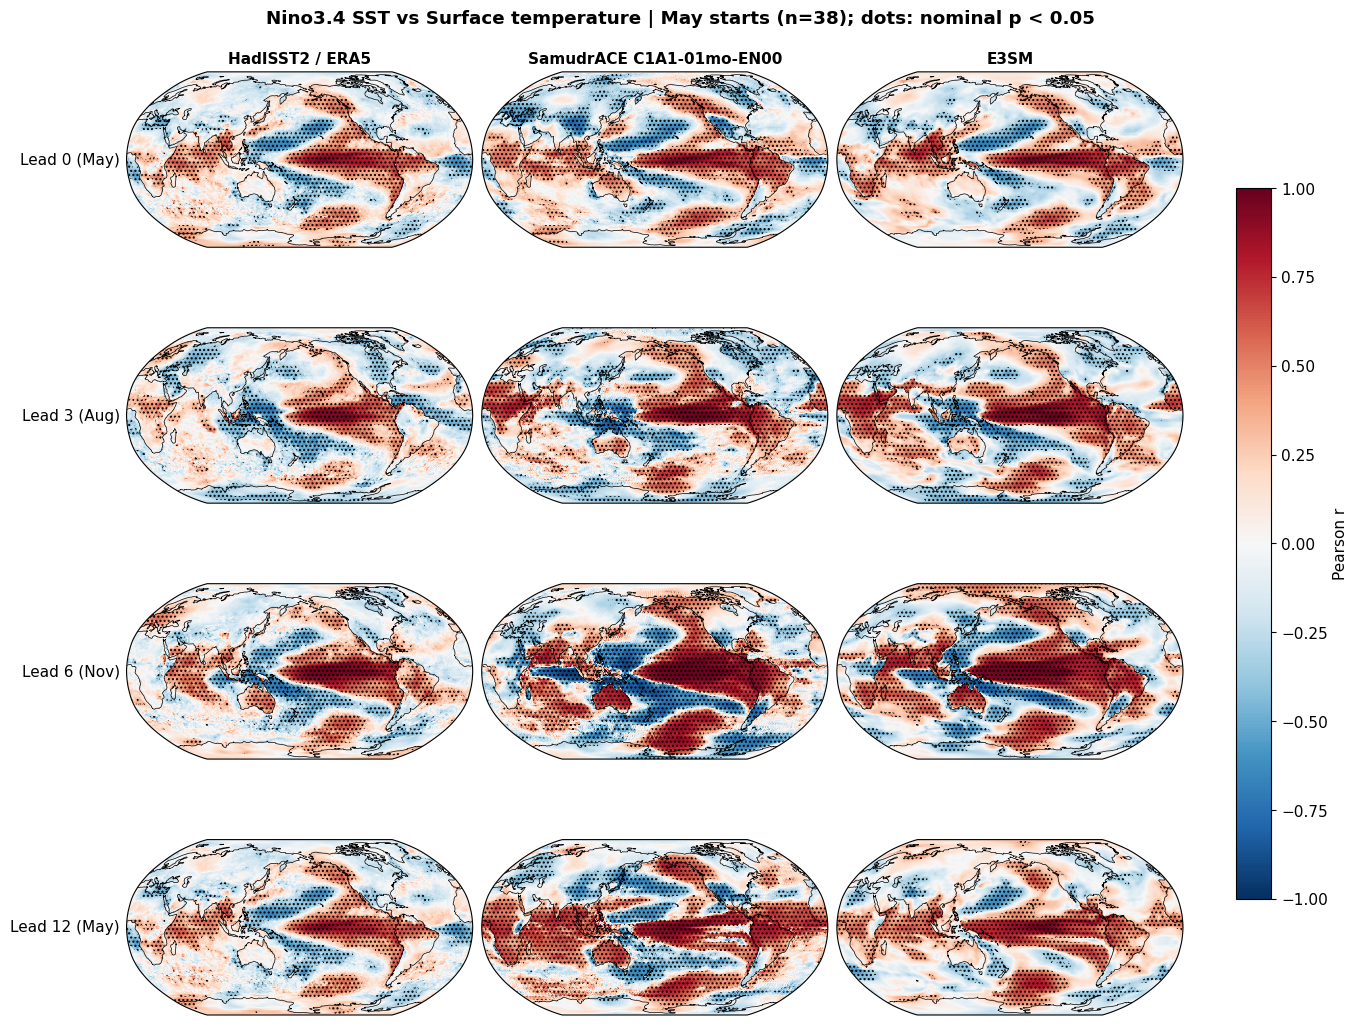

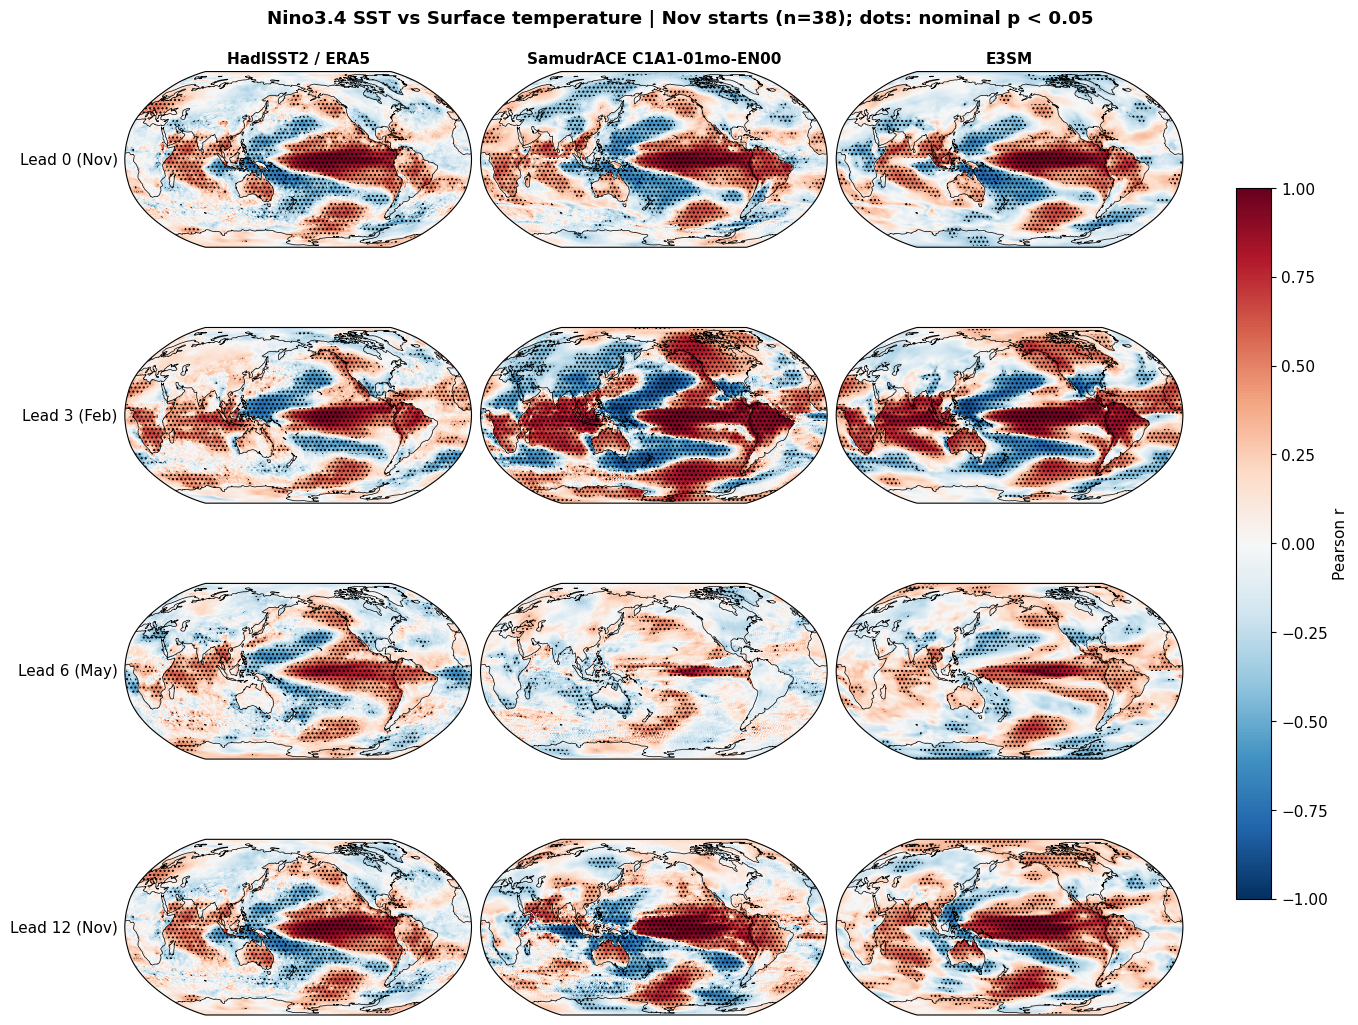

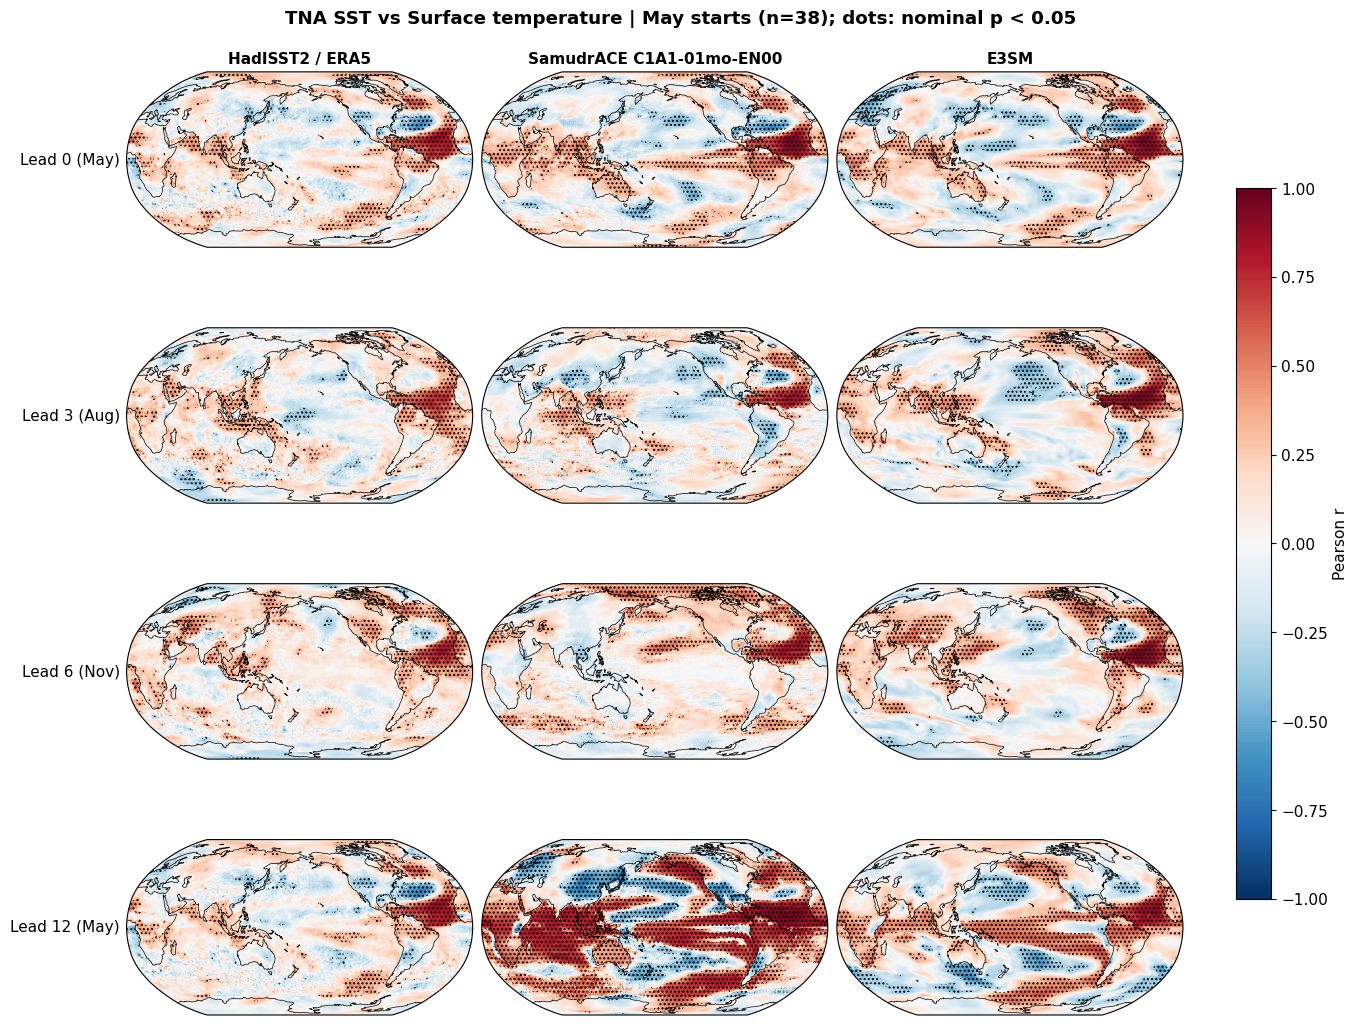

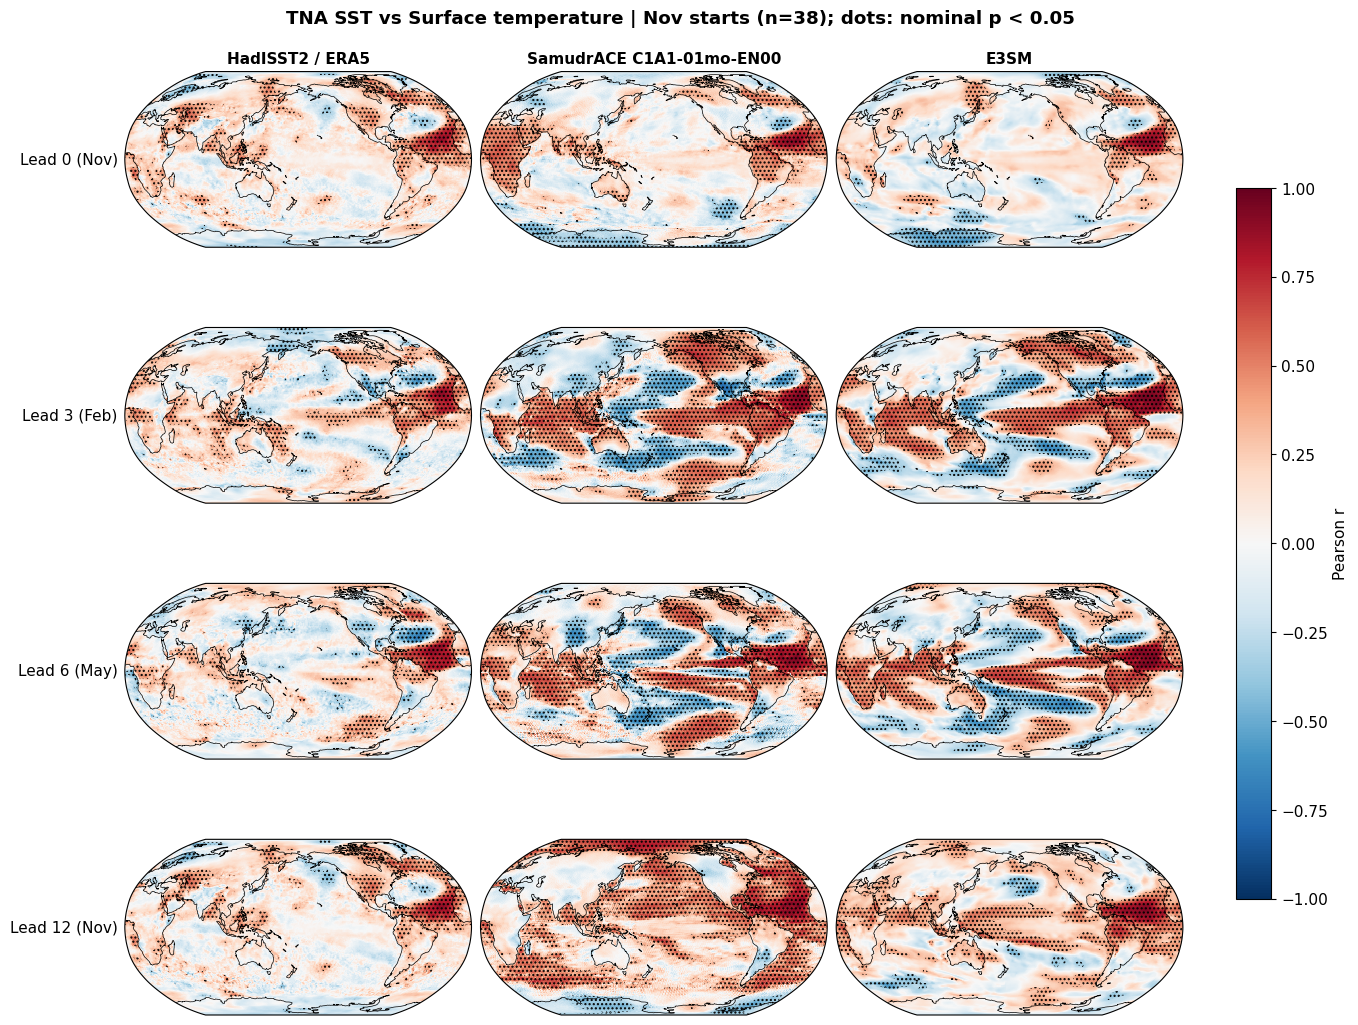

In [10]:
def save_figure(fig, filename):
    if SAVE_FIGURES:
        FIGURE_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIGURE_DIR / filename, dpi=160, bbox_inches="tight")


def plot_maps(ds, variable, name, init_month):
    panel = ds.sel(sst_index=name, init_month=init_month)
    systems = panel.system.values.tolist()
    fig, axes = plt.subplots(
        len(MAP_LEADS), len(systems), figsize=(4.5 * len(systems), 2.45 * len(MAP_LEADS) + 0.7),
        subplot_kw={"projection": ccrs.Robinson(central_longitude=180)},
        squeeze=False, layout="constrained",
    )
    for row, lead in enumerate(MAP_LEADS):
        lead_data = panel.sel(lead=lead)
        month = month_abbr[int(lead_data.verification_month)]
        for col, system in enumerate(systems):
            ax = axes[row, col]
            data = lead_data.sel(system=system)
            im = ax.pcolormesh(data.lon, data.lat, data.correlation, transform=ccrs.PlateCarree(),
                               cmap="RdBu_r", vmin=-1, vmax=1, shading="auto")
            significant = (data.pvalue < ALPHA).where(data.correlation.notnull())
            if bool(significant.fillna(False).any()):
                ax.contourf(data.lon, data.lat, significant, levels=[0.5, 1.5], colors="none",
                            hatches=["...."], transform=ccrs.PlateCarree())
            ax.coastlines(linewidth=0.5)
            if col == 0:
                ax.text(-0.02, 0.5, f"Lead {lead} ({month})", transform=ax.transAxes,
                        ha="right", va="center")
            if row == 0:
                label = f"HadISST2 / {ds.attrs['observational_target']}" if system == "Obs" else DISPLAY[system]
                ax.set_title(label, fontsize=11, fontweight="bold")
    fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.7, label="Pearson r")
    fig.suptitle(f"{name} SST vs {VARIABLE_LABELS[variable]} | {month_abbr[init_month]} starts "
                 f"(n={int(panel.common_start_count)}); dots: nominal p < {ALPHA:g}", fontweight="bold")
    save_figure(fig, f"sst_telecon_{name}_{output_tag(variable)}_init{init_month:02d}.png")
    plt.show()


for variable, ds in results.items():
    for name in SST_INDICES:
        for init_month in INIT_MONTHS:
            plot_maps(ds, variable, name, init_month)

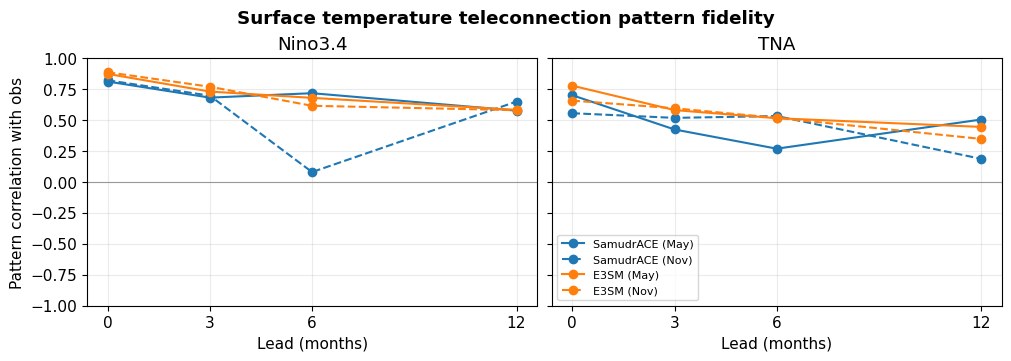

In [11]:
for variable, ds in results.items():
    fig, axes = plt.subplots(1, len(SST_INDICES), figsize=(5 * len(SST_INDICES), 3.5),
                             sharey=True, squeeze=False, layout="constrained")
    for ax, name in zip(axes[0], SST_INDICES):
        for model in MODEL_SYSTEMS:
            for i, init_month in enumerate(INIT_MONTHS):
                curve = ds.pattern_correlation.sel(sst_index=name, model=model, init_month=init_month)
                ax.plot(curve.lead, curve, linestyle=["-", "--", "-.", ":"][i % 4], marker="o",
                        color=f"C{MODEL_SYSTEMS.index(model)}", label=f"{model} ({month_abbr[init_month]})")
        ax.axhline(0, color="0.6", linewidth=0.8)
        ax.set(title=name, xlabel="Lead (months)", xticks=MAP_LEADS, ylim=(-1, 1))
        ax.grid(alpha=0.25)
    axes[0, 0].set_ylabel("Pattern correlation with obs")
    axes[0, -1].legend(fontsize=8)
    fig.suptitle(f"{VARIABLE_LABELS[variable]} teleconnection pattern fidelity", fontweight="bold")
    save_figure(fig, f"sst_telecon_{'_'.join(SST_INDICES)}_{output_tag(variable)}_pattern.png")
    plt.show()